In [1]:
%pip install -U insightface opencv-python huggingface_hub ultralytics

In [1]:
# Import libraries
from huggingface_hub import hf_hub_download
from insightface.model_zoo import get_model
from ultralytics import YOLO
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import pipeline
import os

In [2]:
# Download the pretrained SCRFD-10G model
weights_path = hf_hub_download(
    repo_id="RuteNL/SCRFD-face-detection-ONNX",
    filename="10g_bnkps.onnx"
)

# Load the ONNX model using InsightFace
detector = get_model(weights_path)

# Use GPU if CUDA is available, otherwise use CPU
ctx_id = 0 if torch.cuda.is_available() else -1

# Prepare the model for face detection
detector.prepare(
    ctx_id=ctx_id,
    input_size=(640, 640),
    det_thresh=0.5
)

print("SCRFD model loaded successfully.")

SCRFD model loaded successfully.


In [3]:
def detect_faces(path):
    # Read the input image
    img = cv.imread(path)

    if img is None:
        raise FileNotFoundError(f"Could not find image: {path}")

    # Detect faces and their five facial landmarks
    bboxes, kpss = detector.detect(
        img,
        input_size=(640, 640),
        max_num=0
    )

    # Print the number of detected faces
    print("Number of faces:", len(bboxes))

    # Create a copy of the image for drawing
    annotated = img.copy()

    # Draw a bounding box and confidence score for each face
    for i, face in enumerate(bboxes):
        x1, y1, x2, y2 = np.round(face[:4]).astype(int)
        score = float(face[4])

        cv.rectangle(
            annotated,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv.putText(
            annotated,
            f"Face {score:.2f}",
            (x1, max(20, y1 - 8)),
            cv.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    # Draw the five facial landmarks for each detected face
    if kpss is not None:
        for landmarks in kpss:
            for point in landmarks:
                x, y = np.round(point).astype(int)
                cv.circle(annotated, (x, y), 3, (0, 0, 255), -1)

    # Return the image with detection results
    return annotated

Number of faces: 1
Number of faces: 1
Number of faces: 3
Number of faces: 2
Number of faces: 3
Number of faces: 1
Number of faces: 1
Number of faces: 1
Number of faces: 1
Number of faces: 3


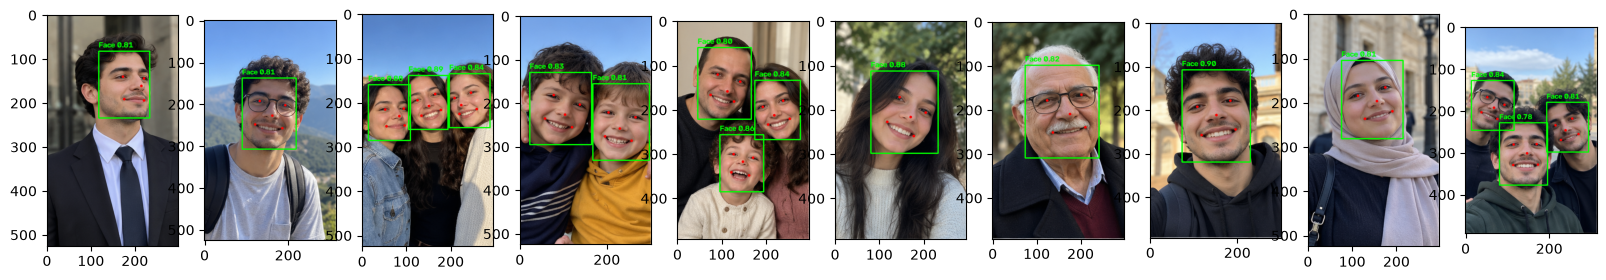

In [4]:
# Set the directory containing the first set of test images
IMAGE_DIR = "test_detection_1"

# Get the paths of all images in the directory
image_paths = [
    os.path.join(IMAGE_DIR, filename)
    for filename in os.listdir(IMAGE_DIR)
]

# Display the detected faces for the first set of images
_, axarr = plt.subplots(1, 10, figsize=(20, 20))
for i, path in enumerate(image_paths):
    faces = detect_faces(path)
    axarr[i].imshow(cv.cvtColor(faces, cv.COLOR_BGR2RGB))
plt.show()

Number of faces: 72
Number of faces: 52
Number of faces: 44


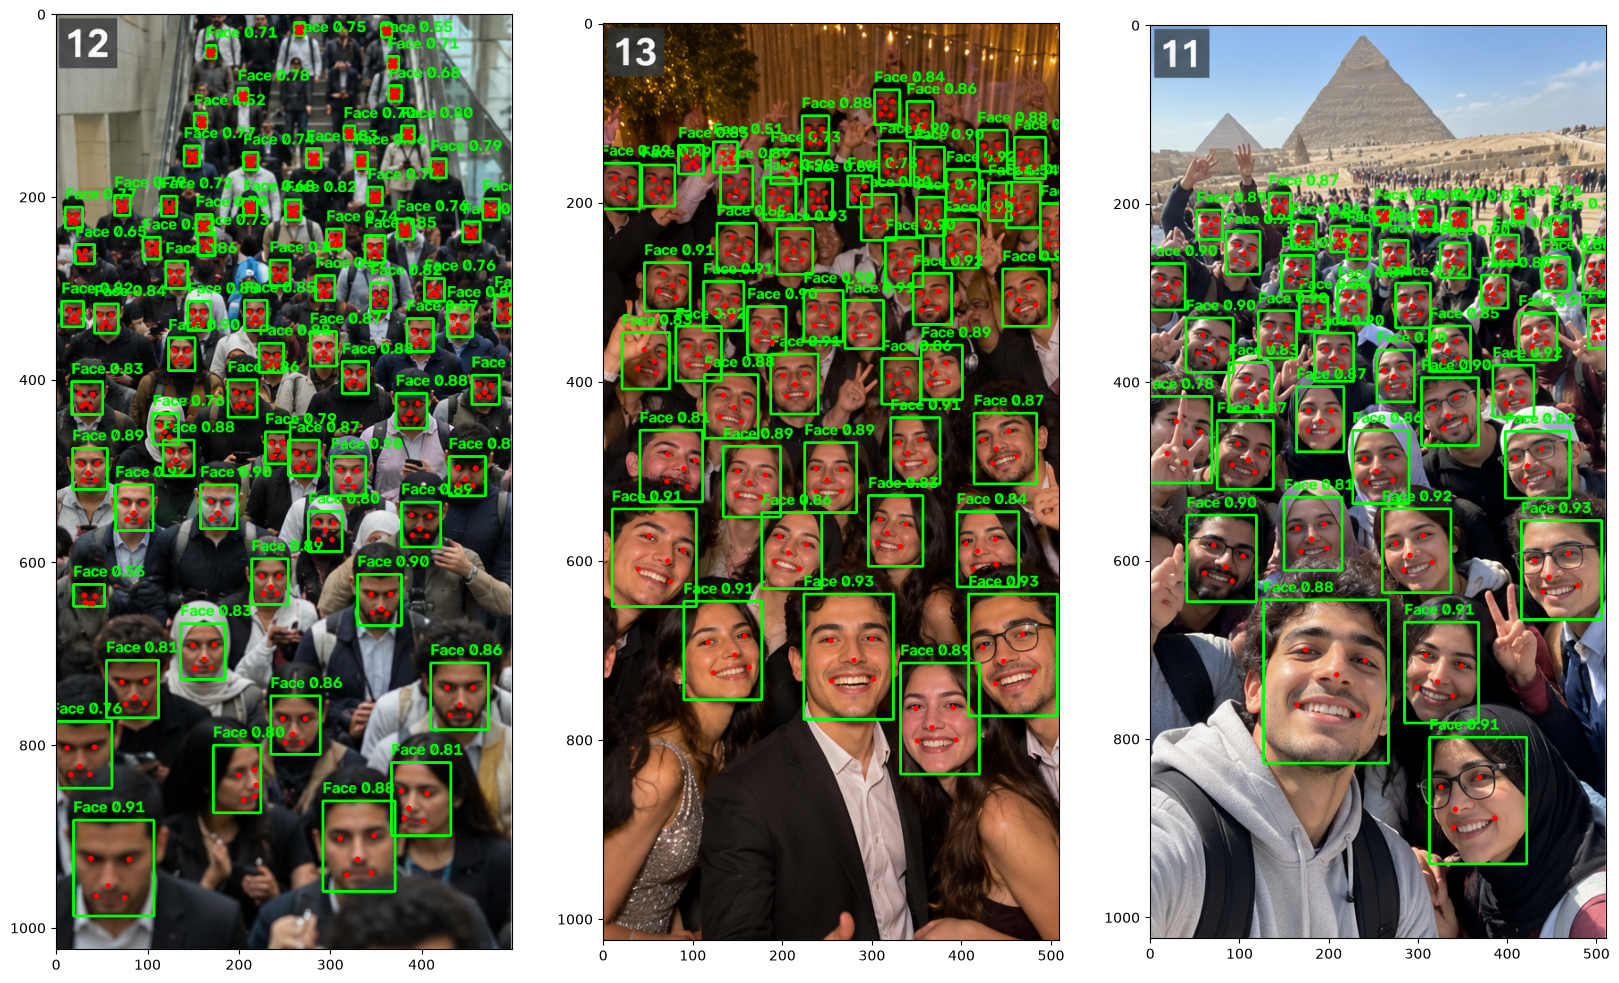

In [5]:
# Set the directory containing the second set of test images
IMAGE_DIR = "test_detection_2"

# Get the paths of all images in the directory
image_paths = [
    os.path.join(IMAGE_DIR, filename)
    for filename in os.listdir(IMAGE_DIR)
]

# Display the detected faces for the second set of images
_, axarr = plt.subplots(1, 3, figsize=(20, 20))
for i, path in enumerate(image_paths):
    faces = detect_faces(path)
    axarr[i].imshow(cv.cvtColor(faces, cv.COLOR_BGR2RGB))
plt.show()

In [ ]:
# Download the pretrained eye detection model
weights_path = hf_hub_download(
    repo_id="MichalMlodawski/open-closed-eye-detection",
    filename="model.pt"
)

# Load the YOLO model
model = YOLO(weights_path)

In [7]:
def detect_eyes(path):
    # Detect eyes in the input image
    results = model.predict(
        source=path,
        conf=0.25,
        imgsz=960
    )

    # Get the prediction results
    result = results[0]

    # Draw bounding boxes and confidence scores
    annotated_image = result.plot(
        labels=False,
        conf=True
    )

    # Return the image with detection results
    return annotated_image


image 1/1 /content/test_detection_1/image_10.png: 960x576 2 closeds, 1704.6ms
Speed: 53.2ms preprocess, 1704.6ms inference, 45.6ms postprocess per image at shape (1, 3, 960, 576)

image 1/1 /content/test_detection_1/image_08.png: 960x576 2 closeds, 607.1ms
Speed: 29.0ms preprocess, 607.1ms inference, 1.5ms postprocess per image at shape (1, 3, 960, 576)

image 1/1 /content/test_detection_1/image_09.png: 960x544 6 closeds, 1 open, 349.2ms
Speed: 5.6ms preprocess, 349.2ms inference, 0.9ms postprocess per image at shape (1, 3, 960, 544)

image 1/1 /content/test_detection_1/image_06.png: 960x576 4 closeds, 3 opens, 244.8ms
Speed: 5.0ms preprocess, 244.8ms inference, 0.9ms postprocess per image at shape (1, 3, 960, 576)

image 1/1 /content/test_detection_1/image_04.png: 960x608 2 closeds, 5 opens, 287.2ms
Speed: 4.7ms preprocess, 287.2ms inference, 1.2ms postprocess per image at shape (1, 3, 960, 608)

image 1/1 /content/test_detection_1/image_02.png: 960x608 1 closed, 2 opens, 291.6ms
Spe

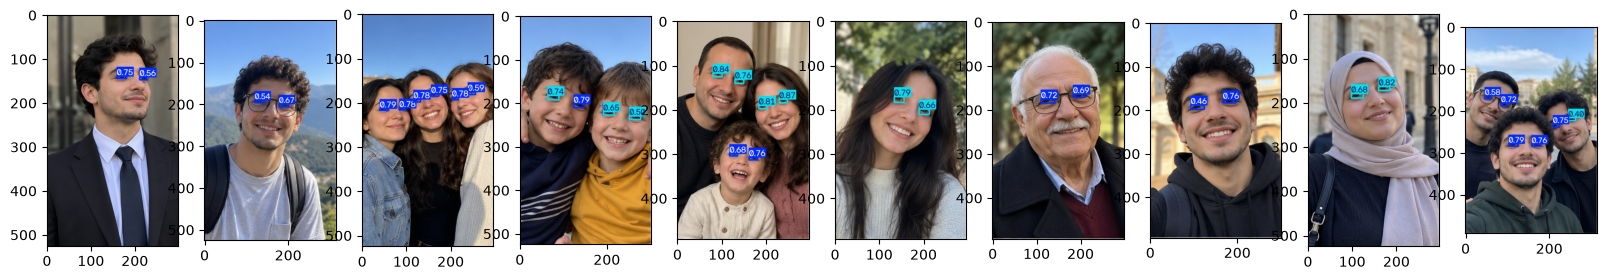

In [8]:
# Set the directory containing the test images
IMAGE_DIR = "test_detection_1"

# Get the paths of all images in the directory
image_paths = [
    os.path.join(IMAGE_DIR, filename)
    for filename in os.listdir(IMAGE_DIR)
]

# Display the detected eyes for all images
_, axarr = plt.subplots(1, 10, figsize=(20, 20))
for i, path in enumerate(image_paths):
    eyes = detect_eyes(path)
    axarr[i].imshow(cv.cvtColor(eyes, cv.COLOR_BGR2RGB))
plt.show()